<a href="https://colab.research.google.com/github/muhammadrakayansyah-beep/afl-raka-/blob/main/LAMA_AIF_P1_25120200002_Muhammad_Rakah_Yansyah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI in Finance / Pertemuan 1
## Cash flow, review output, dan cara ML belajar dari data
Dosen: **Haikal Shiddiq S.Kom., M.T.**  
Universitas Cakrawala / Program Studi Ekonomi, Keuangan, dan Perbankan / Blok B 2026/2027  
Revisi materi 12 November 2026

### Mulai di sini
1. Buka notebook dari tautan pada LMS kelas di Google Colab.
2. Pilih **File > Save a copy in Drive**. Kerjakan salinan pribadi, bukan master dosen.
3. Ubah nama salinan menjadi **AIF_P1_NIM_Nama**. Isi identitas di bawah.
4. Klik **Connect**, lalu jalankan setiap cell dari atas ke bawah dengan tombol segitiga.
5. Pada bagian formulir, ubah angka atau pilihan lalu klik segitiga lagi. Output mengikuti eksekusi terakhir.
6. Isi bagian **Jawaban Anda** dengan membuka cell teks, kemudian simpan. Bagikan salinan kepada email dosen pada LMS sebagai **Viewer**, dan kirim tautan salinan tersebut ke LMS.

Gunakan runtime CPU standar. Latihan kecil ini tidak memerlukan GPU, API key, instalasi Jupyter lokal, atau berkas data tambahan. Data fiktif tersedia secara sengaja di notebook. Semua hasil untuk pembelajaran, bukan keputusan investasi/kredit nyata.

### Python dalam bahasa finance
Python adalah bahasa pemrograman: kita menuliskan langkah agar komputer membaca angka, menghitung rumus, dan menampilkan hasil. Contoh `cash_in - cash_out` mirip rumus selisih di spreadsheet. Fokus Anda adalah makna angka dan keputusan yang didukung, bukan menghafal syntax.
Colab menyediakan tempat menjalankan Python di cloud. Browser menampilkan code dan output; komputer cloud mengerjakan perhitungannya.

Jadwal WIB: AiFn2 Kamis P1 18.00–20.00 dan P2 20.00–22.00 (jeda 20.00–20.10). AiFn1 Jumat P1 08.30–10.00 dan P2 10.00–11.30 (peregangan 10.00–10.03).

Jika perangkat atau koneksi terkendala, kerjakan lembar cadangan individual terlebih dahulu. Catat kendalanya kepada dosen. Eksekusi salinan pribadi tetap perlu dilengkapi pada waktu yang ditetapkan dosen.

### Cara mengikuti bagian ML
Ikuti **Langkah 1 sampai 5** secara berurutan. Kode sudah disediakan; Anda tidak diminta menulis model dari nol. Kita akan melihat data lama, mencoba beberapa batas, lalu memakai batas pilihan untuk memperkirakan pengajuan baru. Angka **jumlah catatan salah** akan dijelaskan terpisah dari **kode status pembayaran**.


In [1]:
# @title Identitas mahasiswa
nama = "Muhammad Rakah Yansyah" # @param {type:"string"}
nim = "25120200002" # @param {type:"string"}
kelas = "AiFn2" # @param ["AiFn2", "AiFn1"]
print(f"Nama: {nama} | NIM: {nim} | Kelas: {kelas}")


Nama: Muhammad Rakah Yansyah | NIM: 25120200002 | Kelas: AiFn2


In [2]:
# @title Persiapan otomatis
import sys
import pandas as pd
import matplotlib.pyplot as plt
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("Siap. Semua data latihan bersifat fiktif.")


Python: 3.13.18
pandas: 2.2.3
Siap. Semua data latihan bersifat fiktif.


## Praktikum 1 / Cash flow sederhana
**Pertanyaan finance:** apakah arus kas bersih setiap bulan surplus atau defisit?

Data awal dalam **Rp juta**: Januari cash in 12 dan cash out 9; Februari 10 dan 11; Maret 15 dan 12.

Rumus: **arus kas bersih = cash in − cash out**. Arus kas bersih bulan ini berbeda dari laba dan berbeda dari saldo akhir yang memerlukan saldo awal.

Jalankan kondisi awal. Setelah itu ubah **cash_in_feb** menjadi **12**, biarkan cash out Februari **11**, lalu jalankan lagi. Bandingkan Februari sebelum dan sesudah perubahan.


   bulan  cash_in_juta  cash_out_juta  arus_kas_bersih_juta
 Januari          12.0            9.0                   3.0
Februari          12.0           11.0                   1.0
   Maret          15.0           12.0                   3.0
Februari awal: 10 - 11 = -1 juta. Skenario sekarang: 1 juta (surplus).


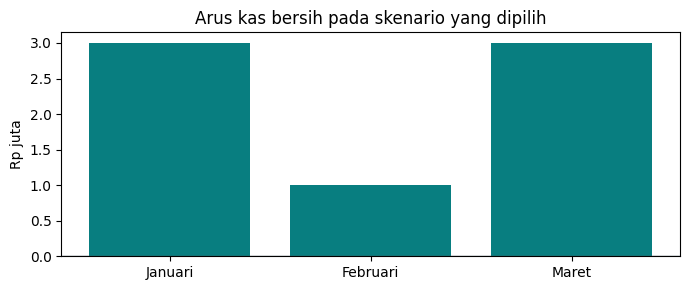

In [3]:
# @title Ubah angka Februari lalu jalankan kembali
cash_in_feb = 12.0 # @param {type:"number"}
cash_out_feb = 11.0 # @param {type:"number"}
if cash_in_feb < 0 or cash_out_feb < 0:
    raise ValueError("Pada latihan ini, isi cash in dan cash out dengan angka nol atau positif.")

cash_flow = pd.DataFrame({
    "bulan": ["Januari", "Februari", "Maret"],
    "cash_in_juta": [12.0, cash_in_feb, 15.0],
    "cash_out_juta": [9.0, cash_out_feb, 12.0]
})
cash_flow["arus_kas_bersih_juta"] = cash_flow["cash_in_juta"] - cash_flow["cash_out_juta"]
print(cash_flow.to_string(index=False))
net_feb = cash_in_feb - cash_out_feb
status_feb = "surplus" if net_feb > 0 else "defisit" if net_feb < 0 else "seimbang"
print(f"Februari awal: 10 - 11 = -1 juta. Skenario sekarang: {net_feb:g} juta ({status_feb}).")
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(cash_flow["bulan"], cash_flow["arus_kas_bersih_juta"], color=["#087E80" if x >= 0 else "#9B443B" for x in cash_flow["arus_kas_bersih_juta"]])
ax.axhline(0, color="#51656C", linewidth=1)
ax.set_ylabel("Rp juta")
ax.set_title("Arus kas bersih pada skenario yang dipilih")
fig.tight_layout()
plt.show()


### Arti code yang baru dijalankan
- `cash_in_feb = 10.0` memberi nama untuk menyimpan suatu angka.
- `pd.DataFrame(...)` menyusun data menjadi tabel.
- `cash_in_juta - cash_out_juta` menghitung selisih per bulan.
- Grafik membantu membaca surplus atau defisit. Perhitungan ini memakai formula yang telah ditentukan manusia.

### Review draft ringkasan
Draft latihan yang sengaja disiapkan dosen: **“Semua bulan menghasilkan surplus kas.”** Ini bukan live output layanan AI.

Pada **data awal**, Februari defisit Rp1 juta sehingga draft perlu dikoreksi. Pada skenario cash in Februari 12 dan cash out 11, kalimat itu cocok dengan tiga angka arus kas bersih yang positif. Cocokkan draft dengan skenario yang benar-benar dijalankan.

Kaitannya dengan generative AI: draft laporan perlu pemeriksaan sumber dan hitungan. Python menghitung dari input; kualitas input tetap perlu ditelaah.


## Latihan 2 Mengenal cara ML belajar dari contoh

Bayangkan Anda sedang mempelajari **empat catatan pinjaman lama**. Rasio cicilan dan hasil pembayarannya sudah diketahui. Kita ingin mencari batas sederhana yang paling cocok dengan empat contoh ini, lalu mencoba batas itu pada pengajuan baru.

**Rasio cicilan** = cicilan bulanan ÷ pendapatan bulanan. Misalnya cicilan Rp3 juta dan pendapatan Rp10 juta menghasilkan rasio **30%**. Pada formulir, angka `30` berarti **30%**, bukan Rp30.

Tiga istilah yang dipakai:
- **Data lama atau historis:** contoh yang hasil pembayarannya sudah diketahui.
- **Belajar atau training:** mencoba pilihan batas dan membandingkannya dengan hasil yang sudah diketahui.
- **Prediksi:** perkiraan untuk pengajuan baru yang hasil pembayarannya belum diketahui.

Kandidat batas **25%, 35%, dan 45%** sengaja disediakan untuk memudahkan latihan. Angka ini bukan ketentuan regulator atau standar persetujuan kredit.

### Langkah 1 Kenali empat catatan lama

Jalankan cell berikut. Baca **riwayat pembayaran** terlebih dahulu, baru kode angkanya:
- **Kode 0 = Tidak terlambat.**
- **Kode 1 = Terlambat.**

Di sini kode 0 dan 1 adalah nama kategori yang disingkat. Keduanya bukan jumlah kesalahan dan bukan besaran risiko.

Untuk percobaan awal, biarkan pilihan pada rasio 40% tetap **Terlambat**. Jangan ubah pilihan ini sebelum menyelesaikan Langkah 5.


In [4]:
# @title Langkah 1 Data lama yang jawabannya sudah diketahui
status_pembayaran_pada_rasio_40 = "Tidak terlambat" # @param ["Terlambat", "Tidak terlambat"]
import pandas as pd

rasio_historis = [20, 30, 40, 50]
label_historis = [0, 0, 1 if status_pembayaran_pada_rasio_40 == "Terlambat" else 0, 1]
kandidat_batas = [25, 35, 45]
data_lama = pd.DataFrame({"rasio_persen": rasio_historis, "label_historis": label_historis})
batas_model = None
prediksi_label = None
review_manual = None

# Fungsi bantu sudah disiapkan dosen. Tidak perlu menulis ulang.
def nama_status(kode):
    return "Terlambat" if kode == 1 else "Tidak terlambat"

def uji_satu_batas(data, batas):
    prediksi = [int(rasio >= batas) for rasio in data["rasio_persen"]]
    salah = [i for i, (tebakan, aktual) in enumerate(zip(prediksi, data["label_historis"])) if tebakan != aktual]
    return {"batas": batas, "prediksi": prediksi, "baris_salah": salah, "jumlah_salah": len(salah)}

def bandingkan_semua_batas(data):
    hasil = [uji_satu_batas(data, batas) for batas in [25, 35, 45]]
    pilihan = min(hasil, key=lambda item: (item["jumlah_salah"], item["batas"]))["batas"]
    return hasil, pilihan

tampilan_lama = pd.DataFrame({
    "Rasio (%)": rasio_historis,
    "Riwayat pembayaran": [nama_status(kode) for kode in label_historis],
    "Kode status": label_historis
})
print("LANGKAH 1 / EMPAT CATATAN LAMA")
print(tampilan_lama.to_string(index=False))
print("\nRiwayat pembayaran di atas adalah jawaban yang sudah diketahui, bukan prediksi.")
print("Kita belum memakai rasio pengajuan baru dalam langkah ini.")


LANGKAH 1 / EMPAT CATATAN LAMA
 Rasio (%) Riwayat pembayaran  Kode status
        20    Tidak terlambat            0
        30    Tidak terlambat            0
        40    Tidak terlambat            0
        50          Terlambat            1

Riwayat pembayaran di atas adalah jawaban yang sudah diketahui, bukan prediksi.
Kita belum memakai rasio pengajuan baru dalam langkah ini.


### Langkah 2 Coba satu batas dan lihat baris yang salah

Sekarang kita mencoba batas **25%** pada **keempat catatan lama**, bukan pada pengajuan baru.

Untuk setiap batas yang dicoba, aturan perkiraannya sama:
- Jika rasio **mencapai atau melebihi batas**, program memperkirakan **Terlambat**.
- Jika rasio **di bawah batas**, program memperkirakan **Tidak terlambat**.

Program lalu mencocokkan perkiraan tersebut dengan riwayat pembayaran. Kolom **Aktual** berarti riwayat pembayaran yang sudah diketahui. **Salah** berarti perkiraannya tidak cocok dengan riwayat tersebut.

**Prediksi dahulu:** dengan batas 25%, rasio 30% akan diperkirakan terlambat. Padahal riwayat 30% adalah tidak terlambat. Jadi ada **1 catatan yang salah**, berasal dari rasio **30%**.

Jalankan cell berikut untuk melihat keempat barisnya. Sesudah itu, boleh mencoba batas 35 atau 45. Cell ini hanya mencoba satu batas; pilihan model secara keseluruhan dihitung pada Langkah 3.


In [5]:
# @title Langkah 2 Coba batas 25 lalu periksa satu per satu
batas_yang_dicoba = 25 # @param {type:"number"}
if "data_lama" not in globals():
    raise ValueError("Jalankan Langkah 1 terlebih dahulu agar data lama tersedia.")
if batas_yang_dicoba not in [25, 35, 45]:
    raise ValueError("Untuk latihan ini, isi batas 25, 35, atau 45. Angkanya berarti persen.")

hasil_satu_batas = uji_satu_batas(data_lama, batas_yang_dicoba)
tabel_rinci = pd.DataFrame({
    "Rasio (%)": data_lama["rasio_persen"],
    "Aktual": [nama_status(kode) for kode in data_lama["label_historis"]],
    "Perkiraan": [nama_status(kode) for kode in hasil_satu_batas["prediksi"]],
    "Hasil": ["SALAH" if i in hasil_satu_batas["baris_salah"] else "BENAR" for i in range(len(data_lama))]
})
print(f"LANGKAH 2 / MENCOBA BATAS {batas_yang_dicoba:g}% PADA DATA LAMA")
print(tabel_rinci.to_string(index=False))
print(f"\nJumlah catatan yang salah: {hasil_satu_batas['jumlah_salah']} dari {len(data_lama)} catatan lama.")
for i in hasil_satu_batas["baris_salah"]:
    baris = data_lama.iloc[i]
    print(f"- Rasio {int(baris['rasio_persen'])}%: perkiraan {nama_status(hasil_satu_batas['prediksi'][i])}, padahal aktualnya {nama_status(int(baris['label_historis']))}.")
if hasil_satu_batas["jumlah_salah"] == 0:
    print("Semua perkiraan cocok dengan empat riwayat pembayaran pada latihan ini.")
print("Jumlah salah adalah banyaknya catatan yang tidak cocok. Ini bukan kode status 0 atau 1.")


LANGKAH 2 / MENCOBA BATAS 25% PADA DATA LAMA
 Rasio (%)          Aktual       Perkiraan Hasil
        20 Tidak terlambat Tidak terlambat BENAR
        30 Tidak terlambat       Terlambat SALAH
        40 Tidak terlambat       Terlambat SALAH
        50       Terlambat       Terlambat BENAR

Jumlah catatan yang salah: 2 dari 4 catatan lama.
- Rasio 30%: perkiraan Terlambat, padahal aktualnya Tidak terlambat.
- Rasio 40%: perkiraan Terlambat, padahal aktualnya Tidak terlambat.
Jumlah salah adalah banyaknya catatan yang tidak cocok. Ini bukan kode status 0 atau 1.


### Langkah 3 Bandingkan tiga batas dan pilih yang paling cocok

Program sekarang mencoba **25%, 35%, dan 45%** pada data lama yang sama. Batas dengan **jumlah catatan salah paling sedikit** akan dipilih.

Pada data awal:
- Batas **25%:** ada **1 catatan salah**, yaitu rasio 30%.
- Batas **35%:** ada **0 catatan salah**.
- Batas **45%:** ada **1 catatan salah**, yaitu rasio 40%.

Karena itu, batas pilihan program adalah **35%**. Inilah ilustrasi belajar dari data: batas dipilih dengan melihat kecocokannya terhadap contoh yang sudah diketahui.

**Penting:** pengajuan baru belum ikut dihitung di sini. Mengubah rasio pengajuan baru menjadi 39%, 29%, atau angka lain **tidak mengubah** jumlah salah pada empat catatan lama, selama data lamanya tetap.


In [6]:
# @title Langkah 3 Bandingkan semua batas pada empat catatan lama
if "data_lama" not in globals():
    raise ValueError("Jalankan Langkah 1 terlebih dahulu agar data lama tersedia.")

hasil_semua_batas, batas_model = bandingkan_semua_batas(data_lama)
salah_per_kandidat = [hasil["jumlah_salah"] for hasil in hasil_semua_batas]
rekap_batas = pd.DataFrame({
    "Batas (%)": [hasil["batas"] for hasil in hasil_semua_batas],
    "Jumlah catatan salah": salah_per_kandidat,
    "Rasio lama yang salah (%)": [
        ", ".join(str(int(data_lama.iloc[i]["rasio_persen"])) for i in hasil["baris_salah"]) or "Tidak ada"
        for hasil in hasil_semua_batas
    ]
})
print("LANGKAH 3 / MEMILIH BATAS DARI DATA LAMA")
print(rekap_batas.to_string(index=False))
print(f"\nBatas pilihan program: {batas_model}%.")
print("Alasan: batas ini mempunyai jumlah catatan salah paling sedikit di antara tiga kandidat.")
print("Angka pada kolom Jumlah catatan salah adalah hitungan catatan, bukan kode Terlambat.")
print("Rasio pengajuan baru belum dipakai. Nol kesalahan di data lama belum menjamin benar di data baru.")


LANGKAH 3 / MEMILIH BATAS DARI DATA LAMA
 Batas (%)  Jumlah catatan salah Rasio lama yang salah (%)
        25                     2                    30, 40
        35                     1                        40
        45                     0                 Tidak ada

Batas pilihan program: 45%.
Alasan: batas ini mempunyai jumlah catatan salah paling sedikit di antara tiga kandidat.
Angka pada kolom Jumlah catatan salah adalah hitungan catatan, bukan kode Terlambat.
Rasio pengajuan baru belum dipakai. Nol kesalahan di data lama belum menjamin benar di data baru.


### Langkah 4 Gunakan batas pilihan untuk pengajuan baru

Baru pada langkah ini kita memasukkan **rasio pengajuan baru**. Hasil pembayarannya belum diketahui; program hanya memberi perkiraan.

Contoh: jika batas pilihan masih **35%** dan pengajuan baru **39%**, maka **39% ≥ 35%**, sehingga perkiraannya **Terlambat**.

Hasil ini berbeda dengan jumlah salah pada langkah sebelumnya:
- **1 catatan salah** = jumlah perkiraan yang tidak cocok pada data lama.
- **Label 1 atau Terlambat** = nama kategori hasil perkiraan.

Jalankan nilai awal 37, lalu coba isi **39** dan jalankan cell ini lagi. Tidak perlu menjalankan ulang Langkah 1–3 jika Anda hanya mengubah rasio baru. Untuk mencoba hasil yang berbeda, isi **29**. Jangan mengubah data lama pada percobaan ini.


In [ ]:
# @title Langkah 4 Masukkan rasio pengajuan BARU lalu lihat perkiraannya
rasio_pengajuan_baru = 37.0 # @param {type:"number"}
prediksi_label = None
review_manual = None
import math
if not math.isfinite(rasio_pengajuan_baru) or not 0 <= rasio_pengajuan_baru <= 100:
    raise ValueError("Isi rasio antara 0 dan 100. Contoh: angka 39 berarti 39%.")
if "data_lama" not in globals():
    raise ValueError("Jalankan Langkah 1 terlebih dahulu agar data lama tersedia.")

# Selalu gunakan data lama yang terakhir dijalankan pada Langkah 1.
_, batas_model = bandingkan_semua_batas(data_lama)
prediksi_label = int(rasio_pengajuan_baru >= batas_model)
hubungan = ">=" if rasio_pengajuan_baru >= batas_model else "<"
print("LANGKAH 4 / PERKIRAAN UNTUK SATU PENGAJUAN BARU")
print(f"Rasio pengajuan baru: {rasio_pengajuan_baru:g}%.")
print(f"Batas pilihan dari data lama: {batas_model}%.")
print(f"Perbandingan: {rasio_pengajuan_baru:g}% {hubungan} {batas_model}%.")
print(f"Hasil perkiraan: {nama_status(prediksi_label)}.")
print(f"Jika ditulis sebagai kode status: {prediksi_label} = {nama_status(prediksi_label)}.")
print("\nIni nama kategori perkiraan, bukan jumlah catatan salah atau probabilitas gagal bayar.")
print("Kita belum tahu apakah perkiraan ini benar karena pembayaran aktual pengajuan baru belum diketahui.")
print("Mengubah rasio BARU tidak mengubah data lama atau jumlah salah pada Langkah 3.")


### Langkah 5 Bedakan perkiraan model dan aturan review manusia

Dalam latihan ini, analis juga mempunyai aturan tetap: **pengajuan dengan rasio 35% atau lebih perlu diperiksa lebih lanjut**.

**Perlu diperiksa** dan **diperkirakan terlambat** menjawab dua pertanyaan yang berbeda. Keduanya belum merupakan keputusan persetujuan atau penolakan kredit.

Jalankan Langkah 4 sebelum cell berikut. Setelah mengubah rasio baru, jalankan kembali Langkah 4, kemudian Langkah 5.


In [ ]:
# @title Langkah 5 Bandingkan dengan aturan review manusia
review_manual = None
if "rasio_pengajuan_baru" not in globals() or "data_lama" not in globals():
    raise ValueError("Jalankan Langkah 1 dan Langkah 4 terlebih dahulu.")
if not math.isfinite(rasio_pengajuan_baru) or not 0 <= rasio_pengajuan_baru <= 100:
    raise ValueError("Perbaiki rasio pada Langkah 4 menjadi angka antara 0 dan 100, lalu jalankan kembali.")

_, batas_model = bandingkan_semua_batas(data_lama)
prediksi_label = int(rasio_pengajuan_baru >= batas_model)
review_manual = rasio_pengajuan_baru >= 35
print(f"LANGKAH 5 / DUA PERTANYAAN UNTUK RASIO BARU {rasio_pengajuan_baru:g}%")
print("Pertanyaan A: Apakah perlu diperiksa menurut aturan manusia dengan batas tetap 35%?")
print("Jawaban A:", "Ya, perlu diperiksa lebih lanjut." if review_manual else "Tidak ditandai oleh aturan ini.")
print(f"\nPertanyaan B: Apa perkiraan dari batas {batas_model}% yang dipilih berdasarkan data lama?")
print("Jawaban B:", nama_status(prediksi_label) + ".")
print("\nTanda perlu diperiksa dan perkiraan status berbeda tujuan. Keduanya bukan keputusan persetujuan kredit.")


### Percobaan lanjutan Mengubah satu riwayat pembayaran lama

Lakukan setelah memahami kelima langkah di atas, bersama dosen.

1. Catat batas pilihan pada data awal dan perkiraan pengajuan baru **37%**. Jika sebelumnya mencoba 39 atau 29, isi kembali 37 pada Langkah 4 dan jalankan Langkah 4–5.
2. Pada **Langkah 1**, ubah `status_pembayaran_pada_rasio_40` menjadi **Tidak terlambat**.
3. Pilih menu **Runtime > Run all** atau **Jalankan semua** agar seluruh tabel dan hasil mengikuti perubahan data lama. Bila memakai tombol segitiga, jalankan Langkah 1 sampai 5 berurutan.
4. Bandingkan jumlah salah, batas yang dipilih, dan perkiraan baru. Dengan riwayat yang berubah, batas pilihan menjadi **45%**. Aturan review manusia tetap **35%** karena aturannya tidak diubah.

Bedakan dua jenis perubahan:
- **Ubah rasio pengajuan baru saja:** yang berubah adalah perkiraan untuk pengajuan tersebut. Data lama dan hasil perbandingan kandidat tetap.
- **Ubah riwayat pembayaran lama:** contoh belajarnya berubah, sehingga batas yang dipilih juga dapat berubah.

Perubahan riwayat pada latihan ini adalah simulasi untuk melihat cara belajar. Data pembayaran nyata hanya boleh dikoreksi berdasarkan bukti.

### Batas kemampuan contoh ini

Hanya ada empat contoh dan tiga pilihan batas. Jumlah salah dihitung pada data yang dipakai untuk belajar, belum pada data pengujian terpisah. Empat kecocokan tidak menjamin perkiraan berikutnya benar. Model tidak menghasilkan probabilitas gagal bayar dan tidak menentukan keputusan kredit nyata.

In [ ]:
# @title Rekap bukti: kondisi awal vs skenario (dijalankan sekaligus agar keduanya tersimpan)
# Cell tambahan mahasiswa. Memakai fungsi dosen dari Langkah 1; data sumber tidak diubah.
cf = pd.DataFrame({"bulan": ["Januari", "Februari", "Maret"],
                   "in_awal": [12.0, 10.0, 15.0], "out_awal": [9.0, 11.0, 12.0],
                   "in_skenario": [12.0, 12.0, 15.0], "out_skenario": [9.0, 11.0, 12.0]})
cf["bersih_awal"] = cf["in_awal"] - cf["out_awal"]
cf["bersih_skenario"] = cf["in_skenario"] - cf["out_skenario"]
status = lambda x: "surplus" if x > 0 else "defisit" if x < 0 else "seimbang"
cf["status_awal"] = cf["bersih_awal"].map(status)
cf["status_skenario"] = cf["bersih_skenario"].map(status)
print("A. ARUS KAS BERSIH (Rp juta)")
print(cf[["bulan", "bersih_awal", "status_awal", "bersih_skenario", "status_skenario"]].to_string(index=False))
print(f"Total 3 bulan: awal {cf['bersih_awal'].sum():g} | skenario {cf['bersih_skenario'].sum():g}")
print("Draft 'Semua bulan surplus' -> data awal:", "SESUAI" if (cf["bersih_awal"] > 0).all() else "TIDAK SESUAI",
      "| skenario:", "SESUAI" if (cf["bersih_skenario"] > 0).all() else "TIDAK SESUAI")

print("\nB. MINI ML: BATAS DARI EMPAT CONTOH")
for nama_kondisi, label40 in [("Awal (40% = Terlambat)", 1), ("Skenario (40% = Tidak terlambat)", 0)]:
    d = pd.DataFrame({"rasio_persen": [20, 30, 40, 50], "label_historis": [0, 0, label40, 1]})
    hasil, batas = bandingkan_semua_batas(d)
    salah = {h["batas"]: h["jumlah_salah"] for h in hasil}
    print(f"{nama_kondisi}: label {d['label_historis'].tolist()} | salah per batas {salah} | batas terpilih {batas}%")
    for r in [37, 39, 29]:
        print(f"   rasio baru {r}%: model -> {nama_status(int(r >= batas))}; aturan manual 35% -> "
              f"{'perlu diperiksa' if r >= 35 else 'tidak ditandai'}; jumlah salah data lama tetap {salah}")


## Tugas praktik P1 Jawaban Anda

- **Nama / NIM / kelas:** Muhammad Rakah Yansyah / 25120200002 / [AiFn1 atau AiFn2]

**A. Arus kas dan draft ringkasan** (Rp juta; arus kas bersih = cash in − cash out)

| Bulan | Data awal | Skenario (Feb in 12, out 11) |
|---|---|---|
| Januari | 12 − 9 = **+3** (surplus) | +3 (surplus) |
| Februari | 10 − 11 = **−1** (defisit) | 12 − 11 = **+1** (surplus) |
| Maret | 15 − 12 = **+3** (surplus) | +3 (surplus) |
| Total 3 bulan | **+5** | **+7** |

- **Februari pada data awal:** −1 juta, artinya defisit: kas keluar Rp1 juta lebih besar daripada kas masuk, sehingga selisihnya harus ditutup dari saldo kas yang ada atau pendanaan lain. **Setelah cash in 12 dan cash out 11:** +1 juta, artinya surplus: kas masuk cukup menutup kas keluar dan tersisa Rp1 juta. Perubahan cash in sebesar +2 juta menggeser hasil Februari dari −1 menjadi +1.
- **Koreksi draft "semua bulan surplus" untuk data awal:** Tidak sesuai. Pada data awal Februari defisit Rp1 juta, jadi yang benar: *"Januari dan Maret surplus masing-masing Rp3 juta, Februari defisit Rp1 juta; total tiga bulan surplus Rp5 juta."* Draft itu baru sesuai untuk skenario (semua bulan positif: +3, +1, +3). Pelajarannya: draft harus dicocokkan dengan data/skenario yang benar-benar dijalankan, bukan diterima begitu saja.
- **Mengapa arus kas bersih ≠ laba atau saldo akhir:** (1) Laba disusun dengan basis akrual: pendapatan diakui saat terjadi, meskipun kasnya belum diterima (piutang), dan beban termasuk pos non-kas seperti penyusutan. Sebaliknya, kas keluar bisa saja bukan beban (misalnya bayar pokok utang atau beli aset). Jadi bulan yang defisit kas bisa tetap laba, dan sebaliknya. (2) Saldo akhir kas = saldo awal + arus kas bersih. Saldo awal tidak tersedia di data ini, sehingga saldo akhir tidak bisa dihitung. Defisit Februari pun belum tentu membuat saldo negatif.

**B. Pola dari empat contoh**

- **Pada data awal, mengapa batas 25% menghasilkan 1 catatan salah? Rasio lama mana yang salah?** Aturannya: rasio ≥ batas diperkirakan Terlambat. Dengan batas 25%, rasio 30% diperkirakan Terlambat, padahal riwayatnya Tidak terlambat. Jadi yang salah adalah **rasio 30%**. Rasio 20% (di bawah 25), serta 40% dan 50% (Terlambat) cocok.
- **Perbedaan "1 catatan salah" dengan "kode status 1":** "1 catatan salah" adalah *hitungan* berapa catatan lama yang perkiraannya tidak cocok dengan riwayat (ukuran kecocokan batas). "Kode status 1" adalah *nama kategori* = Terlambat, label untuk satu catatan/perkiraan. Angkanya sama, maknanya berbeda.
- **Setelah mengubah rasio baru saja menjadi 39%, apakah jumlah salah berubah?** Tidak. Jumlah salah tetap 25%→1, 35%→0, 45%→1, karena dihitung hanya dari empat catatan lama. Rasio pengajuan baru baru dipakai di Langkah 4 untuk prediksi, setelah batas dipilih. Yang berubah hanya perkiraan untuk pengajuan itu (39% ≥ 35% → Terlambat; jika 29% → Tidak terlambat).
- **Perbandingan dengan rasio baru 37%:**

| | Label historis | Salah per batas 25 / 35 / 45 | Batas model | Prediksi 37% | Aturan manual 35% |
|---|---|---|---|---|---|
| Sebelum (40% = Terlambat) | 0/0/1/1 | 1 / 0 / 1 | **35%** | **Terlambat** (37 ≥ 35) | Perlu diperiksa |
| Sesudah (40% = Tidak terlambat) | 0/0/0/1 | 2 / 1 / 0 | **45%** | **Tidak terlambat** (37 < 45) | Perlu diperiksa |

  Satu label yang berubah memindahkan batas model dari 35% ke 45%, sehingga prediksi untuk 37% berbalik. Ini menunjukkan model ini sangat sensitif terhadap sedikit data.
- **Mengapa batas review manusia tetap 35%?** Batas itu ditetapkan oleh analis sebagai aturan tetap (kebijakan "rasio ≥ 35% perlu diperiksa lebih lanjut"), bukan dipelajari dari data. Selama aturannya tidak diubah oleh manusia, batasnya tetap 35% walaupun data historis berubah. Kedua output menjawab pertanyaan berbeda: model menjawab "berdasarkan pola contoh lama, kategori apa perkiraannya?", sedangkan aturan manual menjawab "apakah pengajuan ini perlu ditelaah lebih lanjut?". Keduanya bukan keputusan setuju/tolak kredit.
- **Satu alasan hasil model perlu diperiksa manusia (keterbatasan):** Model hanya belajar dari empat contoh dan tiga kandidat batas, dan jumlah salah dihitung pada data yang sama dengan data belajarnya (tidak ada data uji terpisah). Terbukti: mengubah satu label saja menggeser batas dari 35% ke 45% dan membalik prediksi 37%. Model juga hanya memakai satu variabel (rasio cicilan). Karena itu hasilnya tidak dapat dibaca sebagai probabilitas gagal bayar, dasar persetujuan kredit, atau ketentuan regulator.
- **Bantuan AI:** Alat: Claude (Anthropic). Tujuan: membantu menjalankan notebook untuk kondisi awal dan skenario, menyusun cell rekap perbandingan, dan membuat draf penjelasan jawaban. Bagian yang dibantu: cell "Rekap bukti" dan draf seluruh jawaban di atas. Cara memeriksa: Cara memeriksa: Saya menjalankan sendiri semua cell di Google Colab (Runtime > Run all). Saya juga menghitung ulang arus kas secara manual: Jan 12 − 9 = 3, Feb 10 − 11 = −1, skenario Feb 12 − 11 = 1, Mar 15 − 12 = 3. Saya mencocokkan jumlah catatan salah tiap batas (25/35/45) dengan tabel Langkah 2–3, untuk kondisi awal dan setelah status rasio 40% diubah. Terakhir, saya membaca ulang semua jawaban dan menulisnya dengan kata-kata sendiri.


### Simpan dan kumpulkan tautan

Simpan salinan ke Drive dengan code, output dan jawaban. Berikan email dosen pada LMS akses **Viewer**, lalu kirim tautan **salinan pribadi**, bukan master. Jika kebijakan akun membatasi pembagian, ikuti alternatif file ipynb melalui LMS sesuai arahan dosen. Kuis 1 dikerjakan terpisah. Tenggat mengikuti LMS.


## Rujukan dan batas penggunaan
- RPS resmi prodi, Artificial Intelligence in Finance, 21 Oktober 2026. Sesi 1: peran AI/ML dan kuis. Sesi 2: lingkungan Python/data dan praktikum. Eksplorasi/praproses mendalam dilanjutkan sesi 3.
- Google Colab: https://research.google.com/colaboratory/faq.html
- Python: https://docs.python.org/3/tutorial/introduction.html
- pandas: https://pandas.pydata.org/docs/reference/api/pandas.read_csv.html
- Google Drive sharing: https://support.google.com/drive/answer/2494822

Notebook dan contoh disusun dengan bantuan AI, kemudian kode serta perhitungannya diperiksa. Mahasiswa tetap menjelaskan pemahamannya sendiri dan mendeklarasikan bantuan AI. Data latihan tidak memuat identitas nasabah atau data perusahaan asli.
